# VaR y CVaR de portafolios correlacionados

Se calcula el **Valor en Riesgo (VaR)** y el **VaR Condicional (CVaR)** al 5% de tres portafolios con AAPL, MSFT y NVDA, simulados con correlación mediante Cholesky.

| Portafolio | Pesos $w$ (AAPL, MSFT, NVDA) |
|---|---|
| P1 | [1, 0, 0] |
| P2 | [0.33, 0.33, 0.34] |
| P3 | [0.2, 0.2, 0.6] |

**Inversión inicial:** $V_0 = 100{,}000$ USD

**Contenido:**
1. Simulación de precios correlacionados (mismo método de la actividad anterior).
2. Valor final y pérdidas y ganancias de cada portafolio.
3. VaR y CVaR al 5%.
4. Histogramas con cuartiles, VaR y CVaR.

---

### Librerías

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

---

# Parte 1. Simulación de precios correlacionados

$$S_i(T) = S_i(0)\, e^{\left(r_i - \frac{1}{2}\Sigma_{ii}\right)T + \sqrt{T}\, Z_i}, \qquad Z = L\,\varepsilon$$

- $r_i$: rendimiento anual de la acción, estimado con el último año de datos.
- $\Sigma_{ii}$: varianza anual de la acción (diagonal de la matriz de covarianzas).
- $L$: factor de Cholesky de $\Sigma$.

### Descarga de AAPL, MSFT y NVDA (últimos 3 años)

In [3]:
tickers_tec = ["AAPL", "MSFT", "NVDA"]

data_tec = yf.download(tickers_tec, start="2023-11-01", end="2026-11-01",
                       auto_adjust=True, progress=False)

precios_tec = data_tec["Close"][tickers_tec].dropna()
print(f"Observaciones: {len(precios_tec)}")
precios_tec.tail()

Observaciones: 752


Ticker,AAPL,MSFT,NVDA
Date,,,
2026-10-26,343.910004,532.599976,216.000000
2026-10-27,347.100006,531.330017,217.940002
2026-10-28,343.829987,531.010010,215.380005
2026-10-29,348.910004,530.140015,213.660004
2026-10-30,344.630005,521.909973,204.639999


### Rendimientos logarítmicos y covarianza anualizada

In [4]:
log_ret_tec = np.log(precios_tec / precios_tec.shift(1)).dropna()
covarianza  = log_ret_tec.cov() * 252

covarianza.round(4)

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.0712,0.0231,0.0353
MSFT,0.0231,0.0672,0.0509
NVDA,0.0353,0.0509,0.2168


### Rendimiento esperado de cada acción (último año)

$$r_i = 252 \cdot \overline{\ln\left(\frac{S_t}{S_{t-1}}\right)}$$

In [5]:
r_tec = log_ret_tec.iloc[-252:].mean() * 252

pd.DataFrame({"r (log anual)": r_tec,
              "Rend. simple (%)": (np.exp(r_tec) - 1) * 100}).round(4)

,r (log anual),Rend. simple (%)
Ticker,,
AAPL,0.2488,28.2548
MSFT,-0.0287,-2.8337
NVDA,-0.0093,-0.9224


### Cholesky y choques correlacionados Z = L ε

In [6]:
M = 10_000
T = 1
Sigma = covarianza.values
L = np.linalg.cholesky(Sigma)

np.random.seed(42)
epsilon = np.random.normal(0, 1, [M, len(tickers_tec)])

Z_tec = epsilon @ L.T

### Precios a un año

In [7]:
S0_tec = precios_tec.iloc[-1]
drift  = (r_tec.values - 0.5 * np.diag(Sigma)) * T

ST_tec = S0_tec.values * np.exp(drift + np.sqrt(T) * Z_tec)
ST_tec = pd.DataFrame(ST_tec, columns=tickers_tec)

pd.DataFrame({"S0": S0_tec,
              "Media S_T simulada": ST_tec.mean(),
              "E[S_T] teórico": S0_tec.values * np.exp(r_tec.values * T)}).round(2)

,S0,Media S_T simulada,E[S_T] teórico
AAPL,344.63,441.44,442.00
MSFT,521.91,507.10,507.12
NVDA,204.64,202.40,202.75


---

# Parte 2. Valor final y pérdidas y ganancias

$$V_T = V_0 \sum_i w_i \frac{S_i(T)}{S_i(0)} \qquad \text{P\&L} = V_T - V_0$$

In [8]:
V0 = 100_000

portafolios_tec = {
    "P1": np.array([1, 0, 0]),
    "P2": np.array([0.33, 0.33, 0.34]),
    "P3": np.array([0.2, 0.2, 0.6]),
}

rend_bruto = ST_tec.values / S0_tec.values

VT_tec = pd.DataFrame({nombre: V0 * rend_bruto @ w
                       for nombre, w in portafolios_tec.items()})
PnL = VT_tec - V0

pd.DataFrame({"V_T promedio": VT_tec.mean(),
              "P&L promedio": PnL.mean()}).round(2)

,V_T promedio,P&L promedio
P1,128091.32,28091.32
P2,107961.20,7961.20
P3,104393.50,4393.50


---

# Parte 3. VaR y CVaR

**VaR al 5%:** la pérdida que solo se supera en el 5% de los peores escenarios. Se obtiene del percentil 5% del P&L:

$$\text{VaR}_{5\%} = -\,P_{5\%}(\text{P\&L})$$

Se lee así: "con 95% de confianza, en un año no se pierde más que el VaR".

**CVaR al 5%** (o *Expected Shortfall*): la pérdida **promedio** dentro de ese 5% de peores escenarios:

$$\text{CVaR}_{5\%} = -\,E\left[\text{P\&L} \;\middle|\; \text{P\&L} \le P_{5\%}\right]$$

El VaR dice dónde empieza la cola de pérdidas, pero no qué tan profunda es. El CVaR responde justo eso: si caemos en el 5% malo, cuánto se pierde en promedio. Por eso el CVaR siempre es mayor o igual que el VaR.

**Cuartiles:** $Q_1$, $Q_2$ (mediana) y $Q_3$ dividen los escenarios en cuatro partes iguales. Entre $Q_1$ y $Q_3$ está el 50% central de los resultados.

### Tabla de cuartiles, VaR y CVaR

In [9]:
alpha = 0.05

riesgo = {}
for p in PnL.columns:
    datos = PnL[p]
    p5    = datos.quantile(alpha)
    cola  = datos[datos <= p5]

    riesgo[p] = {
        "Q1": datos.quantile(0.25),
        "Q2 (mediana)": datos.quantile(0.50),
        "Q3": datos.quantile(0.75),
        "Percentil 5%": p5,
        "VaR 5%": -p5,
        "CVaR 5%": -cola.mean(),
        "Escenarios en la cola": len(cola),
    }

riesgo = pd.DataFrame(riesgo).T
riesgo.round(2)

,Q1,Q2 (mediana),Q3,Percentil 5%,VaR 5%,CVaR 5%,Escenarios en la cola
P1,2968.02,23592.61,48170.48,-20258.92,20258.92,28625.00,500.0
P2,-11741.10,4359.07,23226.63,-29159.32,29159.32,35489.19,500.0
P3,-19528.33,-1690.37,22202.23,-38606.37,38606.37,44807.82,500.0


### VaR y CVaR como porcentaje de la inversión

In [10]:
pd.DataFrame({
    "VaR 5% (%)":  riesgo["VaR 5%"]  / V0 * 100,
    "CVaR 5% (%)": riesgo["CVaR 5%"] / V0 * 100,
    "CVaR / VaR":  riesgo["CVaR 5%"] / riesgo["VaR 5%"],
}).round(2)

,VaR 5% (%),CVaR 5% (%),CVaR / VaR
P1,20.26,28.63,1.41
P2,29.16,35.49,1.22
P3,38.61,44.81,1.16


---

# Parte 4. Histogramas con cuartiles, VaR y CVaR

Las barras rojas son el 5% de peores escenarios, es decir, la cola que mide el VaR. Las líneas negras marcan los cuartiles, la naranja el VaR y la morada el CVaR (el promedio de la zona roja).

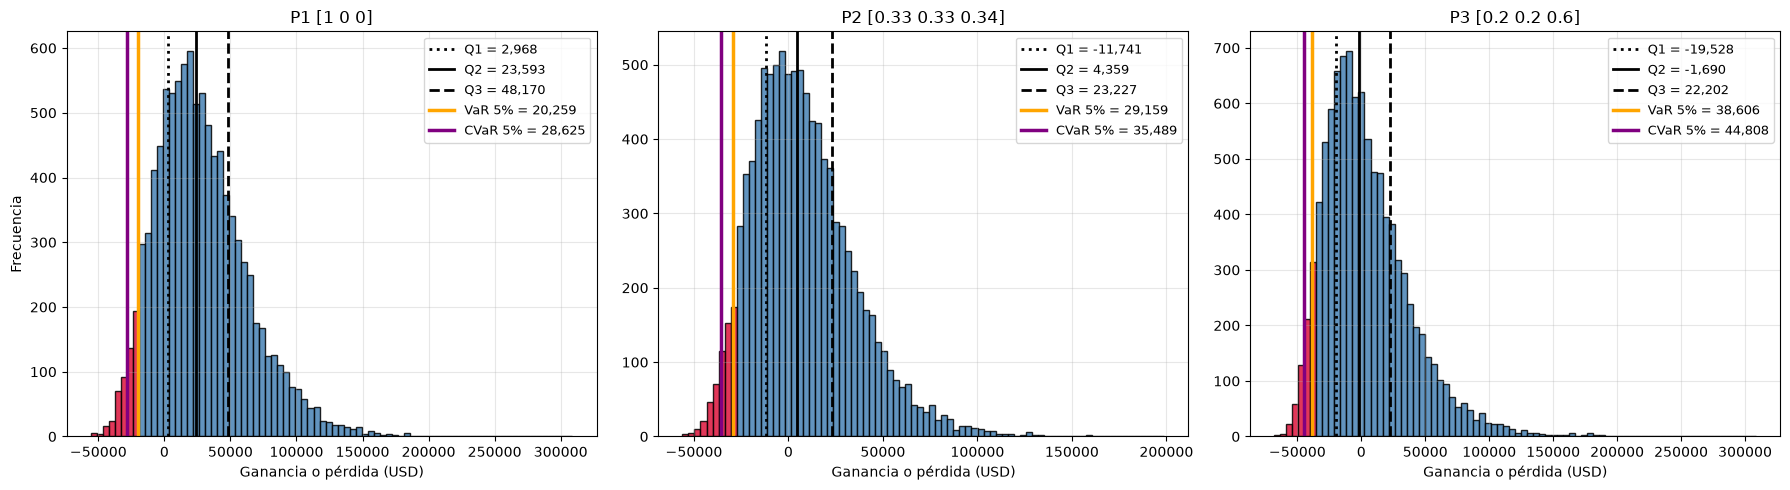

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, p in zip(axes, PnL.columns):
    datos = PnL[p]
    q1, q2, q3 = datos.quantile([0.25, 0.50, 0.75])
    p5   = datos.quantile(alpha)
    cvar = datos[datos <= p5].mean()

    n_barras, bins, barras = ax.hist(datos, bins=80, color="steelblue",
                                     edgecolor="black", alpha=0.85)
    for barra, borde_izq in zip(barras, bins[:-1]):
        if borde_izq < p5:
            barra.set_facecolor("crimson")

    ax.axvline(q1, color="black", ls=":",  lw=2, label=f"Q1 = {q1:,.0f}")
    ax.axvline(q2, color="black", ls="-",  lw=2, label=f"Q2 = {q2:,.0f}")
    ax.axvline(q3, color="black", ls="--", lw=2, label=f"Q3 = {q3:,.0f}")
    ax.axvline(p5,   color="orange", lw=2.5, label=f"VaR 5% = {-p5:,.0f}")
    ax.axvline(cvar, color="purple", lw=2.5, label=f"CVaR 5% = {-cvar:,.0f}")

    ax.set_title(f"{p} {portafolios_tec[p]}")
    ax.set_xlabel("Ganancia o pérdida (USD)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Comparación del VaR y CVaR de los tres portafolios

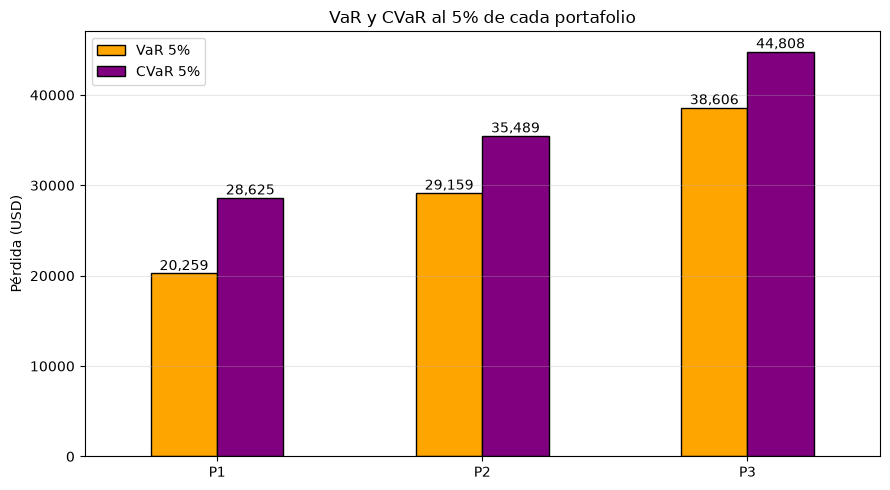

In [13]:
ax = riesgo[["VaR 5%", "CVaR 5%"]].plot(kind="bar", figsize=(9, 5), rot=0,
                                         color=["orange", "purple"], edgecolor="black")
for barras in ax.containers:
        ax.bar_label(barras, fmt="{:,.0f}", fontsize=10)

ax.set_ylabel("Pérdida (USD)")
ax.set_title("VaR y CVaR al 5% de cada portafolio")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

---

# Conclusiones

**1. El VaR de P1 es el más bajo, pero no porque sea el portafolio menos riesgoso.**
P1 tiene un VaR de 20,259 USD (20.3%) y un CVaR de 28,625 USD, los más bajos de los tres, aunque está concentrado en una sola acción. La razón es la tendencia: AAPL tuvo un rendimiento de 28.3% en el último año, y ese crecimiento empuja toda la distribución hacia la derecha. Su primer cuartil es positivo (2,968 USD), es decir, en más del 75% de los escenarios P1 gana dinero. Sin embargo, su rango intercuartil (Q3 menos Q1 = 45,202 USD) es el más ancho de los tres: es el portafolio con más dispersión, solo que centrado en una ganancia.

**2. El VaR mezcla la tendencia con el riesgo.**
En la actividad de pérdidas y ganancias con $\mu = 0$, el percentil 5% de P1 era de -35,555 USD. Ahora, con la tendencia de AAPL, el VaR baja a 20,259. Su volatilidad es la misma; lo único que cambió es el supuesto de crecimiento. En cambio, el VaR de P3 casi no se movió (38,562 contra 38,606), porque MSFT y NVDA tuvieron rendimientos cercanos a cero en el último año. Un VaR bajo puede venir de un activo poco volátil o de suponer que el activo va a seguir subiendo, y esta segunda razón es mucho menos confiable.

**3. P3 es el portafolio con más riesgo de cola.**
Con 60% en NVDA, la acción más volátil, P3 tiene el VaR más alto (38,606 USD, 38.6% de la inversión) y el CVaR más alto (44,808 USD). Además, como NVDA y MSFT tuvieron rendimientos ligeramente negativos, su mediana es negativa (-1,690 USD): en más de la mitad de los escenarios P3 pierde dinero.

**4. P2 queda en medio.**
P2 tiene un VaR de 29,159 USD y un CVaR de 35,489 USD. Reparte el peso entre las tres acciones, así que tiene el rango intercuartil más angosto (34,968 USD), pero solo un tercio de su inversión aprovecha la tendencia positiva de AAPL.

**5. El CVaR siempre es mayor que el VaR, y la diferencia dice qué tan profunda es la cola.**
El VaR marca dónde empieza el 5% de peores escenarios; el CVaR dice cuánto se pierde en promedio dentro de ellos. El cociente CVaR / VaR es 1.41 en P1, 1.22 en P2 y 1.16 en P3. En P1 el cociente es el más alto porque su VaR es bajo gracias a la tendencia, pero cuando cae en la cola la pérdida promedio es 8,366 USD mayor que el VaR: la cola de un solo activo, sin diversificación, es la más larga respecto a donde empieza.

**6. Por qué conviene reportar el CVaR además del VaR.**
Dos portafolios pueden tener el mismo VaR y colas muy distintas, porque el VaR no dice nada de lo que pasa más allá del percentil 5%. El CVaR sí toma en cuenta toda la cola, y por eso es la medida que se prefiere en regulación y gestión de riesgos. Aun así, ambas medidas dependen de los supuestos del modelo: aquí el resultado depende por completo de que el próximo año se parezca al último, sobre todo en el caso de AAPL.